# 01 · How strongly are disclosures supported?

**Reader goal:** distinguish overall support from its variation across disclosures,
tasks, companies and years, and interpret every indicator within its denominator.

**Reading route:** execution coverage → native support distribution → direct and
inferred support → task/company/year variation → secondary indicators and sensitivity.

An evidence claim (EC) is extracted from visible evidence; a disclosure claim (DC)
is extracted from generated text. BACE labels a DC direct if any accepted direct
support set exists; inferred if accepted sets exist but none is direct; otherwise
unsupported. These are automated judgements, not factual-truth labels.

**How to read this notebook.** Each figure begins with a specific question. Its
caption explains the encodings and analysis scope; the following paragraphs
describe the observed pattern, its interpretation, and the remaining limits.
For multi-panel figures, read the individual panels and then their joint meaning.
“Middle half” means the 25th–75th percentiles. In an empirical cumulative
distribution (ECDF), the vertical coordinate is the proportion at or below the
horizontal value; a steep section marks a concentration of observations.
All of this text remains visible when code is hidden.

In [1]:
from pathlib import Path
import sys
analysis_dir = Path.cwd()
if not (analysis_dir / 'analysis_data.py').exists():
    analysis_dir = analysis_dir / 'BACE' / 'analysis'
assert (analysis_dir / 'analysis_data.py').exists(), 'Run from the project root or analysis directory.'
sys.path.insert(0, str(analysis_dir))
sys.dont_write_bytecode = True
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from analysis_data import (load_snapshot, company_bootstrap, case_material, read, rows,
                           save_json, sha, HERE, BACE, ROOT, OUT, CACHE, SEED, METHODS, TASKS, LABELS)
from figure_style import (canvas, save_figure, quote_figure, ecdf, note,
                          BLUE, GREEN, ORANGE, GREY, INK, CMAP,
                          METHOD_COLORS, TYPE_COLORS, LABEL_NAMES, LABEL_COLORS)
tables = load_snapshot()
metrics = tables['metrics']
common = metrics.loc[metrics.bace_complete & metrics.ragchecker_complete & metrics.ragas_complete].copy()
bace = metrics.loc[metrics.bace_complete].copy()
claims = tables['claims']
sample = read(CACHE / 'sample.json')
execution = read(CACHE / 'execution.json')
note(f"**Snapshot:** {len(metrics):,} planned disclosures from {metrics.company_id.nunique()} companies; "
     f"{len(bace):,} complete BACE results and {len(common):,} common completed cases. "
     f"Run status: `{execution['status']}`. All results are automated; no human accuracy benchmark is supplied.")

**Snapshot:** 1,800 planned disclosures from 30 companies; 1,798 complete BACE results and 1,798 common completed cases. Run status: `incomplete`. All results are automated; no human accuracy benchmark is supplied.

**Statistical scope.** The primary unit of presentation is a disclosure (company × year × task).
Repeated disclosures and extracted claims from the same company are dependent.
Where shown, 95% percentile intervals use 2,000 company-cluster bootstrap draws
(seed 20260921), resampling companies with replacement and retaining all their
observed disclosures. These are empirical, unweighted sample summaries, not
design-adjusted population estimates. They do not capture generation/judge
randomness or uncertainty due to the two missing BACE results. Subgroup comparisons
are descriptive; no hypothesis tests, significance stars or causal claims are made.

## 1. Is the analysis cohort complete?

Display completion before scores. Missing BACE branches are not zero support,
and an execution failure does not establish a false generated disclosure.

<a id="reading-01_completion"></a>

**Figure question · 01 completion.** Before interpreting support scores, which planned cases actually have completed results?

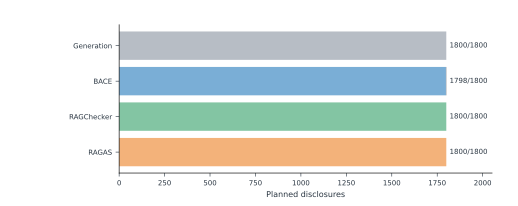

**Read the figure:** bars count completed branches; the narrow dark-grey remainder is missing. No scores are imputed. Completion is read from stage receipts and checked against execution status.

[PDF](outputs/figures/01/01_completion.pdf) · [SVG](outputs/figures/01/01_completion.svg) · [PNG](outputs/figures/01/01_completion.png) · [Source data: data](outputs/figures/01/01_completion__data.csv)

**Pattern and evidence.** Generation, RAGChecker and RAGAS each reach 1,800/1,800. BACE reaches 1,798/1,800 (99.9%), leaving 2 cases. At this scale the missing segment is almost invisible, so the printed counts carry essential information.

**Interpretation.** The generation stage has finished, but the full evaluation run is incomplete. All BACE summaries use observed completed branches, and paired comparisons require completion of all three evaluators.

**Limits and alternative readings.** A 99.9% completion rate does not establish ignorable missingness. The two failures are not zero support and are not evidence of false content. Their exclusion remains visible in the affected company, year and task denominators.

**BACE gaps:** Banco BPM, 2019, S1-5 (partial); Investec, 2023, S1-1 (partial).

In [2]:
status=pd.DataFrame({'stage':['Generation','BACE','RAGChecker','RAGAS'],
                     'complete':[int(metrics.stage_generation.sum()),int(metrics.bace_complete.sum()),int(metrics.ragchecker_complete.sum()),int(metrics.ragas_complete.sum())]})
status['missing']=len(metrics)-status.complete
fig,(ax,)=canvas(height=73,left=.23,right=.95)
ax.barh(status.stage,status.complete,color=[GREY,BLUE,GREEN,ORANGE]);ax.barh(status.stage,status.missing,left=status.complete,color='#6B737C')
ax.invert_yaxis();ax.set_xlabel('Planned disclosures');ax.set_xlim(0,len(metrics)*1.14)
for i,r in enumerate(status.itertuples()):ax.text(len(metrics)*1.01,i,f'{r.complete}/{len(metrics)}',va='center',fontsize=7)
save_figure(fig,'01_completion',status,
    '**Read the figure:** bars count completed branches; the narrow dark-grey remainder is missing. No scores are imputed. Completion is read from stage receipts and checked against execution status.')
missing=metrics.loc[~metrics.bace_complete,['company_name','year','task','state_status']]
note('**BACE gaps:** '+('; '.join(f'{r.company_name}, {r.year}, {r.task} ({r.state_status})' for r in missing.itertuples()) if len(missing) else 'None')+'.')

## 2. What does a typical disclosure look like?

The main score is supported DCs / all deduplicated DCs **within each disclosure**;
the main summary averages those disclosure-level rates. A pooled claim rate gives
more weight to disclosures producing more DCs and is reported separately.

<a id="reading-01_support_distribution"></a>

**Figure question · 01 support distribution.** Among completed cases, is the average score typical, or does it conceal a broad distribution?

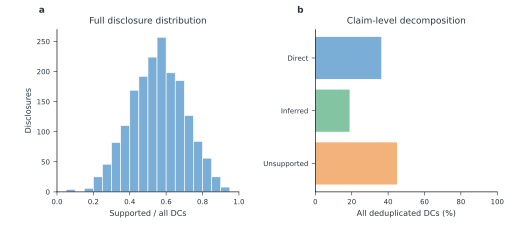

**Read the figure:** panel a gives each disclosure one observation (20 equal-width bins); panel b pools DC counts, so it has a different weighting. All completed BACE disclosures and all their DCs are retained, including non-disclosure statements. Bar heights are observed counts/proportions; the macro interval is reported below.

[PDF](outputs/figures/01/01_support_distribution.pdf) · [SVG](outputs/figures/01/01_support_distribution.svg) · [PNG](outputs/figures/01/01_support_distribution.png) · [Source data: disclosures](outputs/figures/01/01_support_distribution__disclosures.csv) · [Source data: claim_counts](outputs/figures/01/01_support_distribution__claim_counts.csv)

**Pattern and evidence.** Panel a contains 1,798 completed disclosures and has its tallest displayed bin at 55.0%–60.0% (257 disclosures). The median is 55.6%, the middle half spans 45.2%–65.9%, and the 10th–90th percentiles span 35.6%–74.5%. The mean (55.4%; company-cluster 95% interval 53.9%–56.8%) is close to the median, giving no reason to describe pronounced skew. Only 36 disclosures score at most 25%, while 173 reach at least 75%. Panel b partitions all DCs: direct: 34,430 (36.3%); inferred: 17,879 (18.8%); unsupported: 42,646 (44.9%).

**Interpretation.** The broad centre means that a mean near one-half is not a universal score for every disclosure. Direct support supplies the larger supported component, but inferred support contributes materially. The pooled support rate is 55.1%, 0.3 percentage points from the macro mean: similar overall summaries here despite their different weighting.

**Limits and alternative readings.** The modal bin depends on the displayed 0.05 bin width and is not a fitted population mode. Panel a weights disclosures equally; panel b weights DCs equally and gives longer claim inventories more influence. Neither panel measures factual accuracy or includes the two missing BACE branches.

In [3]:
summary=company_bootstrap(bace,'bace_support_rate_all_dc')
fig,axs=canvas(height=87,cols=2,left=.11,right=.96,bottom=.22,top=.88,wspace=.42)
axs[0].hist(bace.bace_support_rate_all_dc,bins=np.linspace(0,1,21),color=BLUE,edgecolor='white',linewidth=.6)
axs[0].set_xlabel('Supported / all DCs');axs[0].set_ylabel('Disclosures');axs[0].set_xlim(0,1);axs[0].set_title('Full disclosure distribution')
parts=pd.DataFrame({'status':['Direct','Inferred','Unsupported'],'count':[bace.bace_supported_direct.sum(),bace.bace_supported_inferred.sum(),bace.bace_unsupported.sum()]})
parts['percent_all_dc']=100*parts['count']/parts['count'].sum()
axs[1].barh(parts.status,parts.percent_all_dc,color=[BLUE,GREEN,ORANGE]);axs[1].invert_yaxis();axs[1].set_xlim(0,100)
axs[1].set_xlabel('All deduplicated DCs (%)');axs[1].set_title('Claim-level decomposition')
save_figure(fig,'01_support_distribution',{'disclosures':bace[['generation_case_id','company_id','bace_support_rate_all_dc']],'claim_counts':parts},
    '**Read the figure:** panel a gives each disclosure one observation (20 equal-width bins); panel b pools DC counts, so it has a different weighting. '
    'All completed BACE disclosures and all their DCs are retained, including non-disclosure statements. Bar heights are observed counts/proportions; the macro interval is reported below.')
pooled=(bace.bace_supported_direct.sum()+bace.bace_supported_inferred.sum())/bace.bace_dc_count.sum()

## 3. Where does support vary across the twelve tasks?

Tasks are displayed in the frozen E1 → S1 → G1 order. Intervals use the same
company-cluster procedure in every row; they are not multiple-comparison tests.

<a id="reading-01_task_support"></a>

**Figure question · 01 task support.** Does the broad disclosure distribution reflect differences between the twelve fixed tasks?

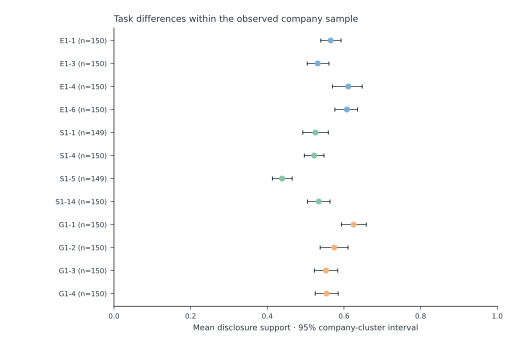

**Read the figure:** points are disclosure-macro means; bars are 95% percentile intervals from 2,000 company-cluster resamples. n in each row counts disclosures; company counts are in source data. **Boundary:** task differences can reflect source relevance, generated content, extraction and judgement together.

[PDF](outputs/figures/01/01_task_support.pdf) · [SVG](outputs/figures/01/01_task_support.svg) · [PNG](outputs/figures/01/01_task_support.png) · [Source data: data](outputs/figures/01/01_task_support__data.csv)

**Pattern and evidence.** S1-5 has the lowest mean (43.9%); G1-1 has the highest (62.5%), a span of 18.6 percentage points. 8 of 12 task means lie between 50% and 60%. Interval widths range from 5.1 to 7.8 percentage points, and many neighbouring task intervals overlap. Colours group E1, S1 and G1 tasks; they do not mark statistical significance.

**Interpretation.** There is a visible low task and a group of higher tasks, but most means occupy a fairly compact middle band. This suggests examining task-specific evidence and claim types, rather than treating the overall mean as equally applicable to every task.

**Limits and alternative readings.** These are descriptive task summaries from the same 30 companies. Overlap or non-overlap of marginal intervals is not a paired, multiplicity-adjusted test of task differences. S1-1 and S1-5 have 149 disclosures; the others have 150. Source availability, generated wording and evaluator behaviour can all contribute to the ordering.

In [4]:
task_stats=pd.DataFrame([{'task':task,**company_bootstrap(bace[bace.task==task],'bace_support_rate_all_dc')} for task in TASKS])
fig,(ax,)=canvas(height=123,left=.22,top=.92,bottom=.12)
for i,r in enumerate(task_stats.itertuples()):
    color={'E1':BLUE,'S1':GREEN,'G1':ORANGE}[r.task.split('-')[0]]
    ax.errorbar(r.mean,i,xerr=[[r.mean-r.low],[r.high-r.mean]],fmt='o',color=color,ecolor=INK,elinewidth=.75,capsize=2,markersize=5)
ax.set_yticks(range(len(task_stats)),[f'{r.task}  (n={r.disclosures})' for r in task_stats.itertuples()]);ax.invert_yaxis()
ax.set_xlim(0,1);ax.set_xlabel('Mean disclosure support · 95% company-cluster interval')
ax.set_title('Task differences within the observed company sample',loc='left')
save_figure(fig,'01_task_support',task_stats,
    '**Read the figure:** points are disclosure-macro means; bars are 95% percentile intervals from 2,000 company-cluster resamples. n in each row counts disclosures; company counts are in source data. '
    '**Boundary:** task differences can reflect source relevance, generated content, extraction and judgement together.')
low=task_stats.loc[task_stats['mean'].idxmin()];high=task_stats.loc[task_stats['mean'].idxmax()]

## 4. Are aggregate results uniform across companies and years?

Every cell below averages completed tasks for one company-year. Grey would mark
an entirely missing company-year; partial cells retain their actual task count in
the source table. The same companies recur across years.

<a id="reading-01_company_year"></a>

**Figure question · 01 company year.** Do the task-level averages conceal persistent company differences or local company-year variation?

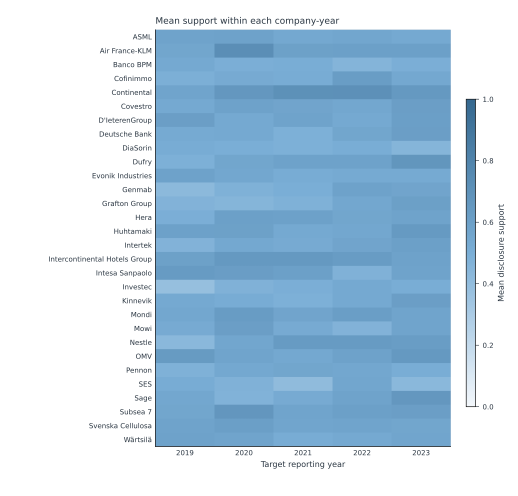

**Read the figure:** fixed 0–1 colour scale, alphabetical rows, no clustering or row normalisation. Cell counts are exported; incomplete tasks are not zeros. **Boundary:** these repeated company-year summaries are descriptive and cannot identify a temporal or company-specific cause.

[PDF](outputs/figures/01/01_company_year.pdf) · [SVG](outputs/figures/01/01_company_year.svg) · [PNG](outputs/figures/01/01_company_year.png) · [Source data: data](outputs/figures/01/01_company_year__data.csv)

**Pattern and evidence.** The middle half of cell values spans 51.2%–59.3%. The lightest cell is Investec, 2019 (38.2%), and the darkest is Air France-KLM, 2020 (72.0%), a 33.8-point span. Equal-year row means range from SES (47.6%) to Continental (65.8%); the median within-row five-year range is 11.5 points. Thus both row differences and within-row changes contribute to the pattern.

**Interpretation.** Some companies have generally darker rows, but changing cells within rows prevent a single stable company ranking from describing everything. The next figure pools completed disclosures within each year to show how much of that local variation survives aggregation.

**Limits and alternative readings.** All 150 company-years are present; 2 cells average 11 tasks and the rest average 12. The fixed 0–1 scale and alphabetical row order avoid artificial contrast from row scaling or clustering. These are support-of-generated-text summaries, not rankings of company ESG quality.

<a id="reading-01_year_support"></a>

**Figure question · 01 year support.** When companies and tasks are aggregated, is there a consistent temporal movement in support?

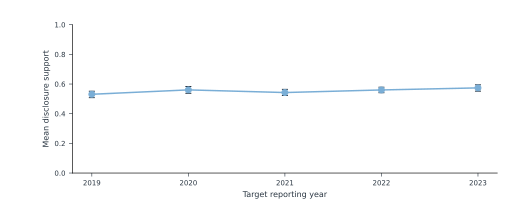

**Read the figure:** each point is a year-specific disclosure-macro mean with a 95% company-cluster bootstrap interval. Connecting lines guide the eye; the same companies recur. **Boundary:** changing source windows and task evidence preclude interpreting this as a causal improvement trend.

[PDF](outputs/figures/01/01_year_support.pdf) · [SVG](outputs/figures/01/01_year_support.svg) · [PNG](outputs/figures/01/01_year_support.png) · [Source data: data](outputs/figures/01/01_year_support__data.csv)

**Pattern and evidence.** The connected means are 2019: 53.1% (n=359); 2020: 56.1% (n=360); 2021: 54.3% (n=360); 2022: 56.0% (n=360); 2023: 57.4% (n=359), with n denoting completed disclosures from 30 recurring companies. The end-to-start difference is 4.3 percentage points, but 1 of the four adjacent changes is downward. The full range of annual means is only 4.3 points; the intervals overlap for several years. The trajectory therefore has fluctuations rather than a monotonic rise.

**Interpretation.** The modest annual spread, compared with the preceding company-year range, shows how aggregation smooths local differences. A later endpoint can coexist with a mid-period decrease and substantial variation within every year.

**Limits and alternative readings.** Lines guide the eye between five repeated annual observations of the same companies. The intervals are marginal company-cluster intervals, not a trend test or an interval for the endpoint difference. Changing evidence windows and two missing task results also constrain temporal interpretation.

In [5]:
cy=bace.groupby(['company_name','company_id','year']).agg(mean=('bace_support_rate_all_dc','mean'),disclosures=('generation_case_id','size')).reset_index()
grid=cy.pivot(index='company_name',columns='year',values='mean').sort_index()
fig,(ax,)=canvas(height=175,left=.30,right=.87,bottom=.10,top=.94)
im=ax.imshow(grid.to_numpy(),vmin=0,vmax=1,cmap=CMAP,aspect='auto');ax.set_facecolor(GREY)
ax.set_yticks(range(len(grid)),grid.index);ax.set_xticks(range(len(grid.columns)),grid.columns);ax.tick_params(length=0)
ax.set_xlabel('Target reporting year');ax.set_title('Mean support within each company-year',loc='left')
cbax=fig.add_axes([.90,.18,.018,.62]);cbax.set_label('<colorbar>');fig.colorbar(im,cax=cbax,label='Mean disclosure support')
save_figure(fig,'01_company_year',cy,
    '**Read the figure:** fixed 0–1 colour scale, alphabetical rows, no clustering or row normalisation. Cell counts are exported; incomplete tasks are not zeros. '
    '**Boundary:** these repeated company-year summaries are descriptive and cannot identify a temporal or company-specific cause.',axes=[ax])
year_stats=pd.DataFrame([{'year':year,**company_bootstrap(bace[bace.year==year],'bace_support_rate_all_dc')} for year in sorted(bace.year.unique())])
fig,(ax,)=canvas(height=73,left=.14)
ax.errorbar(year_stats.year,year_stats['mean'],yerr=[year_stats['mean']-year_stats.low,year_stats.high-year_stats['mean']],fmt='o-',color=BLUE,ecolor=INK,capsize=3)
ax.set_xticks(year_stats.year);ax.set_ylim(0,1);ax.set_xlabel('Target reporting year');ax.set_ylabel('Mean disclosure support')
save_figure(fig,'01_year_support',year_stats,
    '**Read the figure:** each point is a year-specific disclosure-macro mean with a 95% company-cluster bootstrap interval. Connecting lines guide the eye; the same companies recur. '
    '**Boundary:** changing source windows and task evidence preclude interpreting this as a causal improvement trend.')

## 5. What do the secondary indicators add?

- **ECCR:** distinct ECs appearing in any accepted support set / all extracted ECs.
  Alternative sets count toward its numerator. It is neither observed generator use nor ESRS completeness.
- **Inference rate:** DCs supported only by inference / all supported DCs.
- **Sensitivity:** exclude automatically labelled non-disclosure statements from the
  main support denominator. This is explicitly supplementary, not a replacement score.
- A multi-EC support set does not by itself imply inferential support.

<a id="reading-01_secondary_metrics"></a>

**Figure question · 01 secondary metrics.** Do evidence coverage, inferred support and non-disclosure treatment reveal features hidden by the main score?

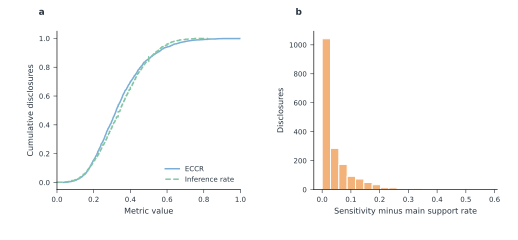

**Read the figure:** panel a shows exact empirical distributions (undefined ratios are excluded and counted below); panel b shows paired changes after removing non-disclosure statements. **Boundary:** a larger secondary metric is not automatically better quality.

[PDF](outputs/figures/01/01_secondary_metrics.pdf) · [SVG](outputs/figures/01/01_secondary_metrics.svg) · [PNG](outputs/figures/01/01_secondary_metrics.png) · [Source data: data](outputs/figures/01/01_secondary_metrics__data.csv)

**Pattern and evidence.** In panel a, ECCR has median 32.3% and middle half 23.7%–42.9%; inference rate has median 34.4% and middle half 25.0%–43.8%. The steep central parts overlap substantially, although their denominators differ. Only 3 disclosures have zero inference rate; undefined values are 0 for ECCR and 0 for inference. Panel b is strongly right-tailed: 641/1798 disclosures have no change, the median increase is 1.9 points, the 90th percentile is 12.7, and the maximum is 58.0. 245 increase by more than ten points; 0 changes are undefined.

**Interpretation.** ECCR and inference are numerically similar near their centres but answer different questions: which ECs appear in accepted sets, and which supported DCs require inference. The sensitivity tail shows that non-disclosure treatment matters much more for a subset of disclosures than for the typical one. Removing an unsupported non-disclosure statement shrinks the denominator without adding supported claims, so the nonnegative shift is partly arithmetic.

**Limits and alternative readings.** Curve overlap does not equate the two secondary constructs. ECCR includes alternative accepted sets and is not observed evidence use. The sensitivity calculation changes the estimand; it does not demonstrate improved generation or identify the preferable denominator.

In [6]:
fig,axs=canvas(height=85,cols=2,left=.11,right=.96,bottom=.21,top=.87,wspace=.40)
for column,color,label,style in [('bace_eccr',BLUE,'ECCR','-'),('bace_inference_rate',GREEN,'Inference rate','--')]:
    ecdf(axs[0],bace[column],color,label,style)
axs[0].set_xlim(0,1);axs[0].set_xlabel('Metric value');axs[0].set_ylabel('Cumulative disclosures');axs[0].legend(loc='lower right')
delta=bace.bace_support_rate_excluding_non_disclosure_sensitivity-bace.bace_support_rate_all_dc
axs[1].hist(delta.dropna(),bins=20,color=ORANGE,edgecolor='white');axs[1].set_xlabel('Sensitivity minus main support rate');axs[1].set_ylabel('Disclosures')
save_figure(fig,'01_secondary_metrics',bace[['generation_case_id','company_id','bace_eccr','bace_inference_rate','bace_non_disclosure_statement','bace_support_rate_all_dc','bace_support_rate_excluding_non_disclosure_sensitivity']],
    '**Read the figure:** panel a shows exact empirical distributions (undefined ratios are excluded and counted below); panel b shows paired changes after removing non-disclosure statements. '
    '**Boundary:** a larger secondary metric is not automatically better quality.')

## What this establishes—and what it leaves open

The reader can now distinguish a typical disclosure from a pooled claim, locate
heterogeneity, and interpret uncertainty at the company level. The next notebook
asks what the unsupported claims actually say. None of these summaries proves
that a company is compliant, that a statement is false in the wider world, or
that the evaluator is correct.

## Reproducibility and interpretation boundary

Each figure is exported to `outputs/figures/` as editable PDF/SVG and 600 dpi PNG,
with its plotted source table(s), caption, and rendered QA records. The snapshot
manifest records source hashes and the verification scope. All observations are
retained unless an explicitly named cohort or case-selection rule is stated.

The source checks cover consumed artifacts and their completed-stage receipts,
shared prompt/context/response identity, and native metric arithmetic. They are
not a new audit of every raw model call or the entire extraction lineage.
Read the final audit report for figure-level visual checks and any reviewed warnings.